<a href="https://colab.research.google.com/github/nishitapjain/DAV/blob/main/exp7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   Hours Studied  ...  Performance Index
0              7  ...               91.0
1              4  ...               65.0
2              8  ...               45.0
3              5  ...               36.0
4              7  ...               66.0

[5 rows x 6 columns]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB
None
       Hours Studied  ...  Performance Index
count  

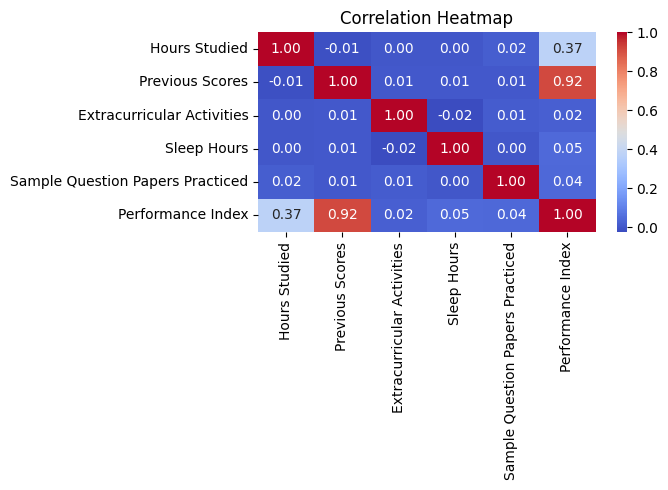


=== SIMPLE LINEAR REGRESSION ===
Intercept (b0): 41.436634826535744
Slope (b1): 2.784300441170774
R2 Score: 0.13160425385996788
RMSE: 17.93919001285204


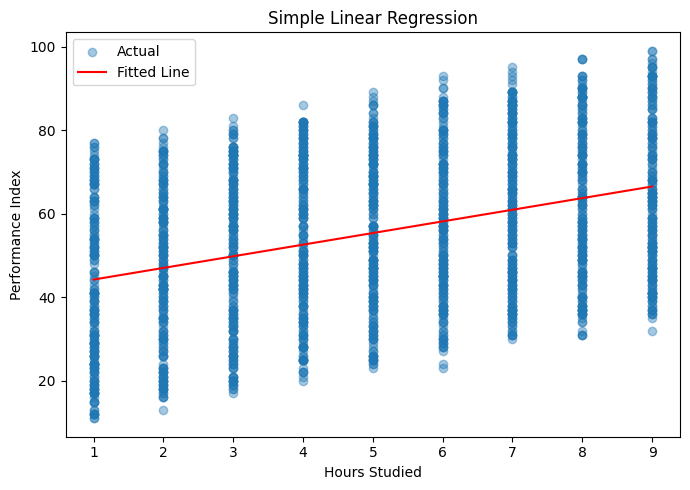


=== MULTIPLE LINEAR REGRESSION =*
Intercept: -33.92194621555638
Hours Studied                       2.8525
Previous Scores                     1.0170
Extracurricular Activities          0.6086
Sleep Hours                         0.4769
Sample Question Papers Practiced    0.1918
R2          : 0.9889832909573145
Adjusted R2 : 0.9889556663107681
RMSE        : 2.0205515085050054

                             OLS Regression Results                            
Dep. Variable:      Performance Index   R-squared:                       0.989
Model:                            OLS   Adj. R-squared:                  0.989
Method:                 Least Squares   F-statistic:                 1.398e+05
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        05:00:53   Log-Likelihood:                -17063.
No. Observations:                8000   AIC:                         3.414e+04
Df Residuals:                    7994   BIC:                      

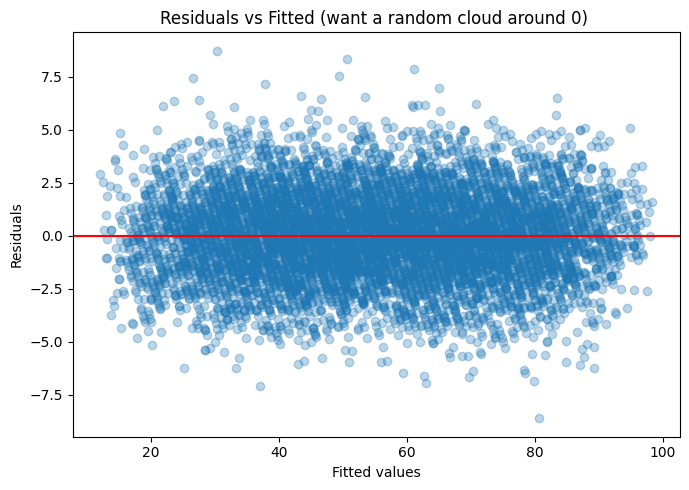

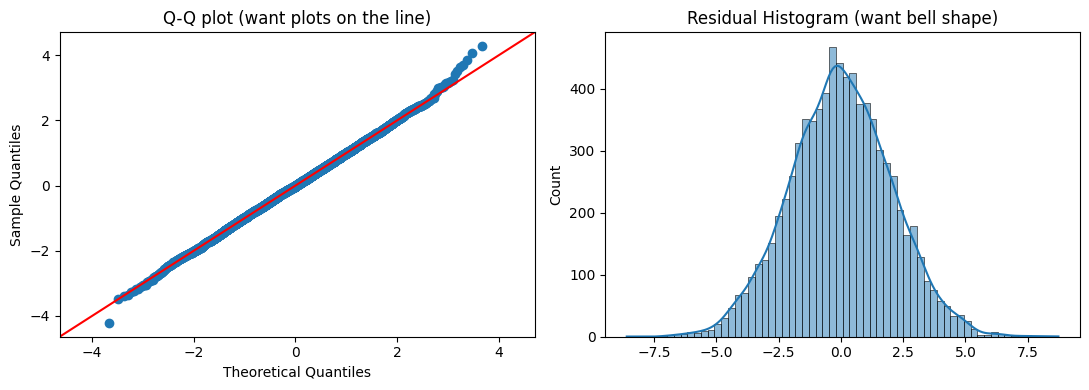

Breusch-Pagan p-value:  0.2396245087908097
Durbin-Watson: 2.0331060225040156

VIF:
                             Feature       VIF
1                     Hours Studied  1.000387
2                   Previous Scores  1.000243
3        Extracurricular Activities  1.000428
4                       Sleep Hours  1.000461
5  Sample Question Papers Practiced  1.000320


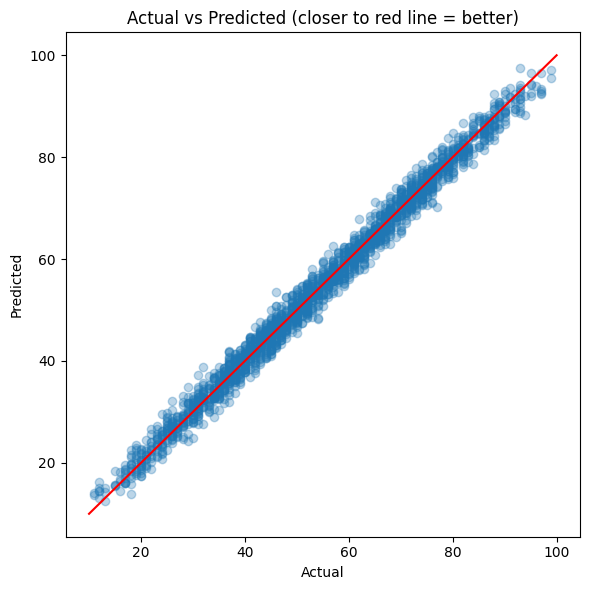

In [36]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error


df = pd.read_csv("/content/archive (2).zip")

print(df.head())
print(df.info())
print(df.describe())

print("Missing Values:\n", df.isnull().sum())

df["Extracurricular Activities"] = df[
    "Extracurricular Activities"
].map({"Yes": 1, "No": 0})

plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(numeric_only=True), annot=True,
            cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("01_correlation.png")
plt.show()

X_simple = df[["Hours Studied"]]
y = df["Performance Index"]

Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(Xs_train, ys_train)

print("\n=== SIMPLE LINEAR REGRESSION ===")
print("Intercept (b0):", simple_model.intercept_)
print("Slope (b1):", simple_model.coef_[0])

ys_pred = simple_model.predict(Xs_test)

print("R2 Score:", r2_score(ys_test, ys_pred))
print("RMSE:", np.sqrt(mean_squared_error(ys_test, ys_pred)))

plt.figure(figsize=(7, 5))
plt.scatter(Xs_test["Hours Studied"], ys_test, alpha=0.4, label="Actual")
sorted_indices = Xs_test["Hours Studied"].argsort()
plt.plot(
    Xs_test["Hours Studied"].iloc[sorted_indices],
    ys_pred[sorted_indices],
    color="red",
    label="Fitted Line"
)
plt.xlabel("Hours Studied")
plt.ylabel("Performance Index")
plt.legend()
plt.title("Simple Linear Regression")
plt.tight_layout()
plt.savefig("02_simple_fit.png")
plt.show()

X = df.drop(columns= "Performance Index")
x_train, x_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42
)
multi_model = LinearRegression()
multi_model.fit(x_train, y_train)
print("\n=== MULTIPLE LINEAR REGRESSION =*")
print("Intercept:", multi_model.intercept_)
for name, coef in zip(X.columns, multi_model.coef_):
    print(f"{name:35s} {coef:.4f}")
y_pred = multi_model. predict (x_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
n, p = x_test. shape
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
print ("R2          :", r2)
print ("Adjusted R2 :", adj_r2)
print ("RMSE        :", rmse)

x_train_sm = sm.add_constant(x_train)
ols = sm.OLS(y_train, x_train_sm). fit()
print("\n", ols.summary())

fitted = ols.fittedvalues
resid=ols.resid

plt.figure(figsize=(7, 5))
plt.scatter(fitted, resid, alpha=0.3)
plt.axhline(0, color="red")
plt.xlabel ("Fitted values")
plt.ylabel( "Residuals")
plt.title( "Residuals vs Fitted (want a random cloud around 0) ")
plt.tight_layout ()
plt.savefig("03_resid_vs_fitted.png")
plt.show()

fig, ax = plt.subplots(1, 2, figsize = (11, 4))
sm.qqplot(resid, line = "45", fit = True, ax = ax[0])
ax[0].set_title("Q-Q plot (want plots on the line)")
sns.histplot(resid, kde = True, ax = ax[1])
ax[1].set_title("Residual Histogram (want bell shape)")
plt.tight_layout()
plt.savefig("04_normality.png")
plt.show()

bp_stat, bp_p, _, _ = het_breuschpagan (resid, x_train_sm)
print("Breusch-Pagan p-value: ", bp_p)

print("Durbin-Watson:", durbin_watson (resid))

vif = pd.DataFrame({
    "Feature": x_train_sm.columns,
    "VIF": [
        variance_inflation_factor(x_train_sm.values, i)
        for i in range(x_train_sm.shape[1])
    ]
})
print("\nVIF:\n", vif[vif["Feature"] != "const"])

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    color='red'
)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted (closer to red line = better)")
plt.tight_layout()
plt.savefig("05_actual_vs_pred.png")
plt.show()


